In [1]:
import sys
sys.path.append("../src")

from preprocessing import load_and_clean_attrition

df = load_and_clean_attrition("../data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv")
df.to_csv("../data/processed/attrition_clean.csv", index=False)

print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print("Attrition Rate:\n", df["Attrition"].value_counts(normalize=True).round(3) * 100)

Rows: 1470, Columns: 32
Attrition Rate:
 Attrition
No     83.9
Yes    16.1
Name: proportion, dtype: float64



--- OverTime ---
          Employees  Attrition_Rate
OverTime                           
Yes             416            30.5
No             1054            10.4

--- Department ---
                        Employees  Attrition_Rate
Department                                       
Sales                         446            20.6
Human Resources                63            19.0
Research & Development        961            13.8

--- JobRole ---
                           Employees  Attrition_Rate
JobRole                                             
Sales Representative              83            39.8
Laboratory Technician            259            23.9
Human Resources                   52            23.1
Sales Executive                  326            17.5
Research Scientist               292            16.1
Manufacturing Director           145             6.9
Healthcare Representative        131             6.9
Manager                          102             4.9
Research Director    

/var/folders/58/kvtz58kj4bz6d72_2fp5zhd40000gn/T/ipykernel_24744/3973303822.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="OverTime", y="Attrition_Flag", ax=axes[0], palette="Set2")
/var/folders/58/kvtz58kj4bz6d72_2fp5zhd40000gn/T/ipykernel_24744/3973303822.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Attrition", y="MonthlyIncome", ax=axes[1], palette="Set2")


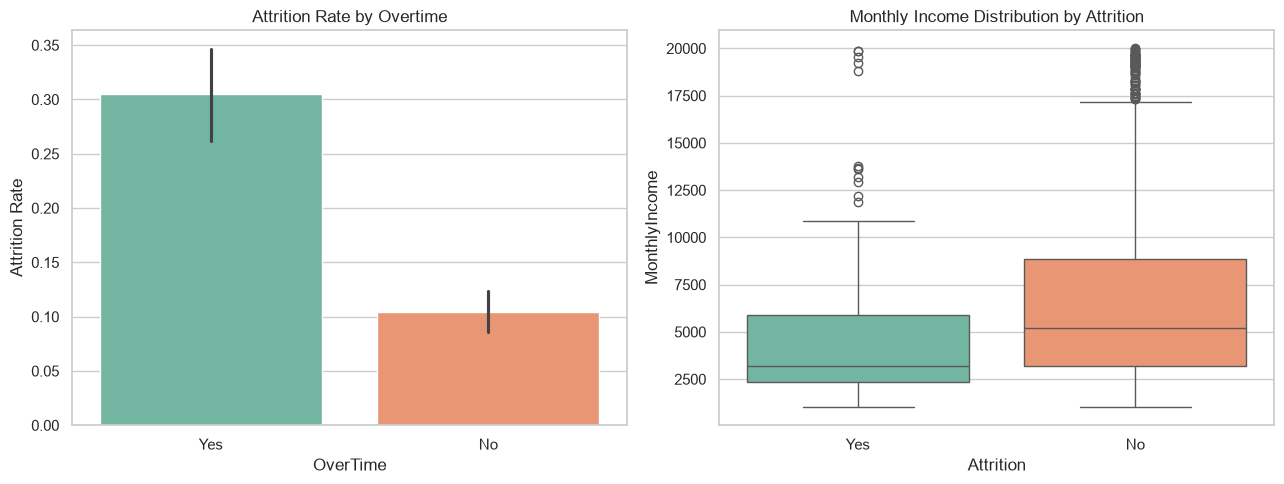

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Attrition rate across key categorical drivers
drivers = ["OverTime", "Department", "JobRole", "BusinessTravel", "MaritalStatus"]
for col in drivers:
    summary = (
        df.groupby(col)["Attrition_Flag"]
        .agg(Employees="count", Attrition_Rate="mean")
        .sort_values("Attrition_Rate", ascending=False)
    )
    summary["Attrition_Rate"] = (summary["Attrition_Rate"] * 100).round(1)
    print(f"\n--- {col} ---")
    print(summary)

# 2. Plot Overtime & Monthly Income vs Attrition
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(data=df, x="OverTime", y="Attrition_Flag", ax=axes[0], palette="Set2")
axes[0].set_title("Attrition Rate by Overtime")
axes[0].set_ylabel("Attrition Rate")

sns.boxplot(data=df, x="Attrition", y="MonthlyIncome", ax=axes[1], palette="Set2")
axes[1].set_title("Monthly Income Distribution by Attrition")

plt.tight_layout()
plt.savefig("../outputs/figures/key_attrition_drivers.png", dpi=150)
plt.show()

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

df_model = df.copy()
df_model["Promotion_Lag_Ratio"] = df_model["YearsSinceLastPromotion"] / (df_model["YearsAtCompany"] + 1)
df_model["Tenure_Per_Company"] = df_model["TotalWorkingYears"] / (df_model["NumCompaniesWorked"] + 1)

X = pd.get_dummies(df_model.drop(columns=["Attrition", "Attrition_Flag"]), drop_first=True)
y = df_model["Attrition_Flag"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced", random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]
    print(f"\n=== {name} (ROC-AUC: {roc_auc_score(y_test, probs):.3f}) ===")
    print(classification_report(y_test, preds, target_names=["Stayed", "Quit"]))


=== Logistic Regression (ROC-AUC: 0.794) ===
              precision    recall  f1-score   support

      Stayed       0.92      0.78      0.84       247
        Quit       0.35      0.64      0.45        47

    accuracy                           0.76       294
   macro avg       0.64      0.71      0.65       294
weighted avg       0.83      0.76      0.78       294


=== Random Forest (ROC-AUC: 0.749) ===
              precision    recall  f1-score   support

      Stayed       0.87      0.93      0.90       247
        Quit       0.42      0.28      0.33        47

    accuracy                           0.82       294
   macro avg       0.65      0.60      0.62       294
weighted avg       0.80      0.82      0.81       294



In [5]:
rf = models["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Top 10 Attrition Predictors:\n", importances.head(10).round(4))

Top 10 Attrition Predictors:
 Tenure_Per_Company    0.0763
MonthlyIncome         0.0605
Age                   0.0564
DailyRate             0.0462
TotalWorkingYears     0.0440
OverTime_Yes          0.0433
MonthlyRate           0.0420
HourlyRate            0.0417
DistanceFromHome      0.0414
YearsAtCompany        0.0396
dtype: float64
